# Coronary Heart Disease Prediction on NHANES 2013-2014: Data Audit and Model Revalidation

**Author:** Ziang Zhang

This notebook re-examines the BIOL 485 project that replicated a published PSO-ANN model for coronary heart disease (CHD) on NHANES 2013-2014.

1. Audits the merged dataset and shows that 15,103 labeled rows belong to only **5,751 participants**.
2. Builds a clean, one-row-per-person cohort with clinical risk categories (the fact table behind the Power BI dashboard).
3. Shows that the original train/test split leaked duplicated participants into both sets.
4. Re-evaluates logistic regression, random forest and KNN with participant-level cross-validation.
5. Quantifies uncertainty (bootstrap CIs), tunes the decision threshold for screening, compares SMOTE-inside-fold with class weighting, and reports logistic-regression odds ratios.
6. Checks calibration (calibration curve, Brier score, calibration slope) and clinical usefulness (decision curve analysis).
7. Tests how much the results depend on the missing-data strategy (mean, missing indicators, MICE, dropping triglycerides, complete cases).
8. Estimates CHD prevalence for U.S. adults with the NHANES survey design (MEC weights, strata, PSUs; Taylor-linearized SEs).
9. Fits a survey-weighted logistic regression (design-based sandwich SEs, the estimator behind R `svyglm`) with multiple imputation and Rubin's rules, verified against a stratified jackknife.
10. Exports every table the Power BI report uses to `outputs/`.

**Inputs** (in `data/`):
- `selected_features_v1.csv`: the merged output of the **original** preprocessing notebook (with the duplicated participants). Keep this file so the audit stays reproducible.
- `train_split_smote.csv`, `test_split.csv`: the original modeling splits.
- `raw/demographic.csv`: for the survey design variables (`WTMEC2YR`, `SDMVSTRA`, `SDMVPSU`).

**Environment:** `pip install -r requirements.txt` (pandas, scikit-learn, imbalanced-learn, matplotlib).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Works when run from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


## 1. Data audit: rows versus participants

The original notebook merged six NHANES files on the participant ID `SEQN` with an outer join. Five files have one row per person, but the **medications file has one row per prescription**, so every participant was repeated once per medication.

In [2]:
v1_path = DATA_DIR / "selected_features_v1.csv"
if not v1_path.exists():  # older layout
    v1_path = DATA_DIR / "selected_features.csv"
raw = pd.read_csv(v1_path).rename(columns={"Blood-Rel Stroke": "StrokeHistory"})
labeled = raw[raw["disease_status"].notna()]

funnel = pd.DataFrame(
    [
        ("Rows after merging six NHANES files", len(raw)),
        ("Unique participants (SEQN)", raw["SEQN"].nunique()),
        ("Rows with a valid CHD label", len(labeled)),
        ("Unique participants with a valid CHD label", labeled["SEQN"].nunique()),
    ],
    columns=["Step", "Count"],
)
funnel["Order"] = range(1, len(funnel) + 1)
funnel.to_csv(OUT_DIR / "funnel.csv", index=False)
funnel

,Step,Count,Order
0,Rows after merging six NHANES files,20194,1
1,Unique participants (SEQN),10175,2
2,Rows with a valid CHD label,15103,3
3,Unique participants with a valid CHD label,5751,4


Participants appearing once: 3,311
Participants appearing 2+ times: 2,440
Maximum rows for one participant: 23
Average rows per participant: 2.63
Extra rows from repeated SEQN: 9,352; of these, fully identical: 9,352


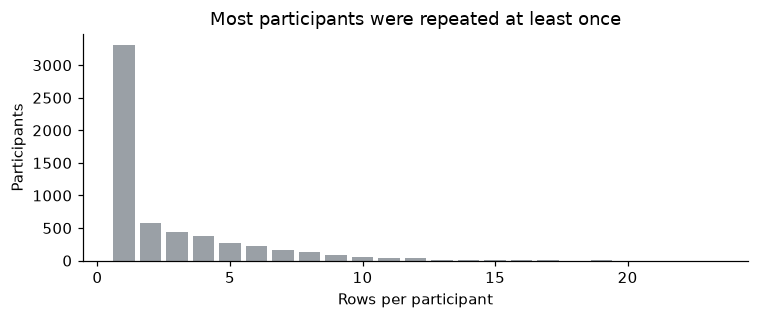

In [3]:
rows_per_person = labeled.groupby("SEQN").size()
dup_dist = rows_per_person.value_counts().sort_index()
print(f"Participants appearing once: {dup_dist.loc[1]:,}")
print(f"Participants appearing 2+ times: {dup_dist.loc[2:].sum():,}")
print(f"Maximum rows for one participant: {rows_per_person.max()}")
print(f"Average rows per participant: {len(labeled) / labeled['SEQN'].nunique():.2f}")

# Are the duplicates identical on every analysis variable?
n_dup_rows = labeled.duplicated(subset=[c for c in labeled.columns]).sum()
n_dup_seqn = labeled.duplicated(subset="SEQN").sum()
print(f"Extra rows from repeated SEQN: {n_dup_seqn:,}; of these, fully identical: {n_dup_rows:,}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(dup_dist.index, dup_dist.values, color="#9aa0a6")
ax.set_xlabel("Rows per participant")
ax.set_ylabel("Participants")
ax.set_title("Most participants were repeated at least once")
plt.tight_layout()
plt.show()

**Fix at the source.** In the original merge, the medications file should be collapsed to one row per `SEQN` before joining (for example, a count of prescriptions), or left out because none of the 19 model variables comes from it:

```python
meds = pd.read_csv(RAW_DIR / "medications.csv", usecols=["SEQN"])
meds_per_person = meds.groupby("SEQN").size().rename("n_prescriptions").reset_index()
```

Below, the cohort is deduplicated on `SEQN`, which gives the same result because the duplicated rows are identical.

## 2. Person-level cohort with clinical categories

One row per participant, with categories based on common clinical thresholds. Labels start with a number so they sort correctly in Power BI.

Note: the original feature called "Blood-Rel Stroke" comes from `MCQ160F`, which asks whether the **participant** was ever told they had a stroke. It is renamed `StrokeHistory` here.

In [4]:
d = labeled.drop_duplicates("SEQN").reset_index(drop=True)

cohort = pd.DataFrame({
    "SEQN": d["SEQN"],
    "Sex": d["Gender"],
    "Age": d["Age"],
    "AgeGroup": pd.cut(d["Age"], [19, 39, 59, 200], labels=["20-39", "40-59", "60+"]).astype(str),
    "CHD": np.where(d["disease_status"] == "diseased", "Yes", "No"),
    "CHD_Flag": (d["disease_status"] == "diseased").astype(int),
    "SystolicBP": d["Systolic"],
    "DiastolicBP": d["Diastolic"],
    "TotalCholesterol": d["Cholesterol"],
    "HDL": d["HDL"],
    "Triglycerides": d["Triglycerides"],
    "Glucose": d["Glucose"],
    "HbA1c": d["Glycohemoglobin"],
    "Creatinine": d["Creatinine"],
    "UricAcid": d["Uric Acid"],
    "LDH": d["LDH"],
    "PlateletCount": d["Platelet Count"],
    "RDW": d["Red-Cell Distribution Width"],
})

def bp_category(sys_bp, dia_bp):
    if pd.isna(sys_bp) or pd.isna(dia_bp):
        return "Missing"
    if sys_bp >= 140 or dia_bp >= 90:
        return "4 Stage 2 hypertension"
    if sys_bp >= 130 or dia_bp >= 80:
        return "3 Stage 1 hypertension"
    if sys_bp >= 120:
        return "2 Elevated"
    return "1 Normal"

def binned(series, edges, labels):
    out = pd.cut(series, edges, labels=labels).astype(object)
    return out.where(series.notna(), "Missing")

cohort["BPCategory"] = [bp_category(s, x) for s, x in zip(d["Systolic"], d["Diastolic"])]
cohort["HbA1cCategory"] = binned(d["Glycohemoglobin"], [0, 5.69, 6.49, 100],
                                 ["1 Normal (<5.7%)", "2 Prediabetes (5.7-6.4%)", "3 Diabetes range (>=6.5%)"])
cohort["CholesterolCategory"] = binned(d["Cholesterol"], [0, 199.9, 239.9, 1000],
                                       ["1 Desirable (<200)", "2 Borderline (200-239)", "3 High (>=240)"])
low_hdl = ((d["Gender"] == "Male") & (d["HDL"] < 40)) | ((d["Gender"] == "Female") & (d["HDL"] < 50))
cohort["LowHDL"] = np.where(d["HDL"].isna(), "Missing", np.where(low_hdl, "Low", "Not low"))
cohort["DiabetesSelfReport"] = d["Diabetes"].map({1: "Yes", 2: "No", 3: "Borderline"}).fillna("Unknown")
cohort["VigorousWork"] = d["Vigorous Work"].map({1: "Yes", 2: "No"}).fillna("Unknown")
cohort["ModerateWork"] = d["Moderate Work"].map({1: "Yes", 2: "No"}).fillna("Unknown")
cohort["FamilyHistoryDiabetes"] = d["Blood-Rel Diabetes"].map({1: "Yes", 2: "No"}).fillna("Unknown")
cohort["StrokeHistory"] = d["StrokeHistory"].fillna("Unknown")

# NHANES design variables, so Power BI can compute survey-weighted prevalence
design = pd.read_csv(DATA_DIR / "raw" / "demographic.csv", usecols=["SEQN", "WTMEC2YR", "SDMVSTRA", "SDMVPSU"])
cohort = cohort.merge(design, on="SEQN", how="left", validate="one_to_one")
assert cohort["SEQN"].is_unique and len(cohort) == len(d)
cohort.to_csv(OUT_DIR / "nhanes_chd_cohort.csv", index=False)
print(f"Participants: {len(cohort):,}; CHD cases: {cohort['CHD_Flag'].sum()} ({cohort['CHD_Flag'].mean():.1%})")
print(f"Median age: {cohort['Age'].median():.0f}; sex: {cohort['Sex'].value_counts().to_dict()}")

Participants: 5,751; CHD cases: 232 (4.0%)


Median age: 48; sex: {'Female': 3003, 'Male': 2748}


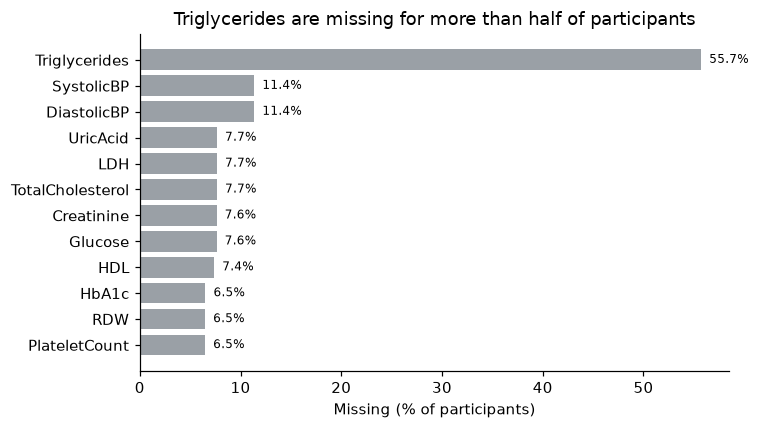

In [5]:
lab_vars = ["SystolicBP", "DiastolicBP", "TotalCholesterol", "HDL", "Triglycerides", "Glucose",
            "HbA1c", "Creatinine", "UricAcid", "LDH", "PlateletCount", "RDW"]
missing = cohort[lab_vars].isna().mean().sort_values()
(missing.rename("MissingShare").rename_axis("Variable").reset_index()
        .to_csv(OUT_DIR / "missingness.csv", index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(missing.index, missing.values * 100, color="#9aa0a6")
ax.set_xlabel("Missing (% of participants)")
ax.set_title("Triglycerides are missing for more than half of participants")
for y, v in enumerate(missing.values):
    ax.text(v * 100 + 0.8, y, f"{v:.1%}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

## 3. CHD prevalence by risk group

Unweighted prevalence in this sample. NHANES survey weights were not included, so these figures describe the sample, not U.S. adults.

In [6]:
groups = {
    "Age group": "AgeGroup",
    "Sex": "Sex",
    "Blood pressure": "BPCategory",
    "HbA1c": "HbA1cCategory",
    "Self-reported diabetes": "DiabetesSelfReport",
    "Stroke history": "StrokeHistory",
}
tables = []
for name, col in groups.items():
    t = (cohort[~cohort[col].isin(["Missing", "Unknown"])]
         .groupby(col)["CHD_Flag"].agg(cases="sum", n="count").reset_index()
         .rename(columns={col: "Level"}))
    t.insert(0, "Factor", name)
    tables.append(t)
prevalence = pd.concat(tables, ignore_index=True)
prevalence["Prevalence"] = (prevalence["cases"] / prevalence["n"]).round(4)
prevalence.to_csv(OUT_DIR / "prevalence_by_group.csv", index=False)
prevalence

,Factor,Level,cases,n,Prevalence
0,Age group,20-39,6,1953,0.0031
1,Age group,40-59,41,1971,0.0208
2,Age group,60+,185,1827,0.1013
3,Sex,Female,93,3003,0.0310
4,Sex,Male,139,2748,0.0506
5,Blood pressure,1 Normal,65,2304,0.0282
6,Blood pressure,2 Elevated,44,825,0.0533
7,Blood pressure,3 Stage 1 hypertension,31,1032,0.0300
8,Blood pressure,4 Stage 2 hypertension,68,936,0.0726
9,HbA1c,1 Normal (<5.7%),63,3351,0.0188


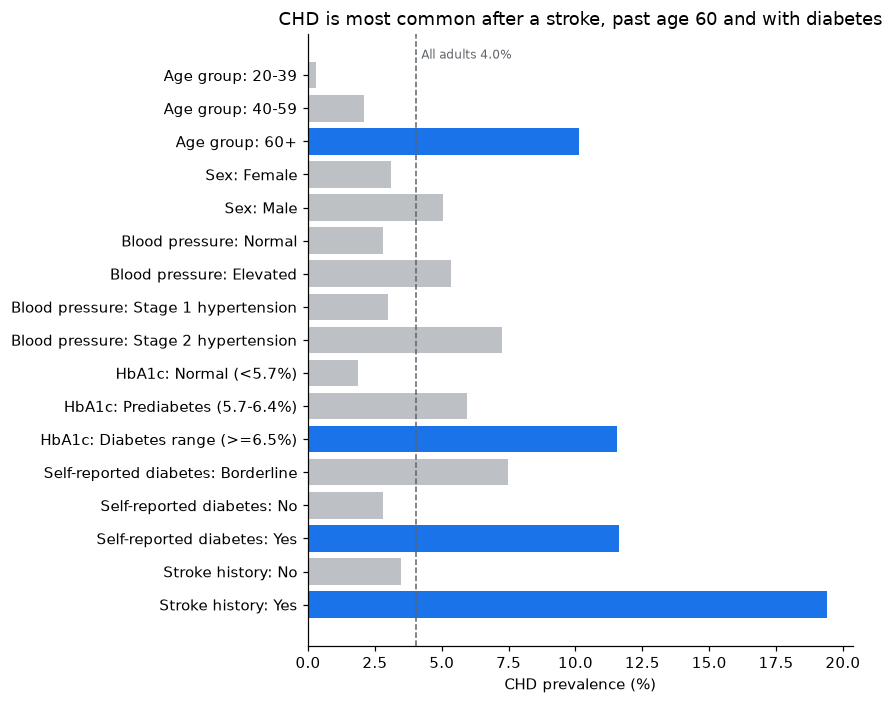

In [7]:
plot_df = prevalence.iloc[::-1]
labels = plot_df["Factor"] + ": " + plot_df["Level"].astype(str).str.replace(r"^\d ", "", regex=True)
colors = ["#1a73e8" if p >= 0.10 else "#bdc1c6" for p in plot_df["Prevalence"]]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(labels, plot_df["Prevalence"] * 100, color=colors)
overall = cohort["CHD_Flag"].mean() * 100
ax.axvline(overall, color="#5f6368", linestyle="--", linewidth=1)
ax.text(overall + 0.2, len(plot_df) - 0.5, f"All adults {overall:.1f}%", fontsize=8, color="#5f6368")
ax.set_xlabel("CHD prevalence (%)")
ax.set_title("CHD is most common after a stroke, past age 60 and with diabetes")
plt.tight_layout()
plt.show()

## 4. Leakage check: does the test set contain training rows?

The original notebook split **rows**, not people, so copies of the same participant could land in both the training and test sets.

In [8]:
train = pd.read_csv(DATA_DIR / "train_split_smote.csv")
test = pd.read_csv(DATA_DIR / "test_split.csv")
features = [c for c in test.columns if c not in ("disease_status", "SEQN")]

train_keys = set(map(tuple, train[features].round(6).to_numpy()))
test["in_train"] = [tuple(r) in train_keys for r in test[features].round(6).to_numpy()]

print(f"Test rows with an exact copy in the training set: {test['in_train'].mean():.1%}")
print(test.groupby("disease_status")["in_train"].mean().map("{:.1%}".format))

Test rows with an exact copy in the training set: 75.4%
disease_status
diseased    97.8%
normal      72.9%
Name: in_train, dtype: str


## 5. Model evaluation: original setup versus corrected setup

**Original:** models trained on the SMOTE-balanced training rows and tested on the row-level test set.

**Corrected:** one row per participant, stratified 5-fold cross-validation, imputation and scaling fit inside each fold, and class weighting instead of SMOTE. KNN has no class weights, so its threshold is set to the outcome rate.

In [9]:
def scores(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "AUC": roc_auc_score(y_true, prob),
        "Accuracy": accuracy_score(y_true, pred),
        "Sensitivity": recall_score(y_true, pred, pos_label=1),
        "Specificity": recall_score(y_true, pred, pos_label=0),
    }

results = []

# Original setup
y_train = (train["disease_status"] == "diseased").astype(int)
y_test = (test["disease_status"] == "diseased").astype(int)
original_models = {
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}
for name, model in original_models.items():
    model.fit(train[features], y_train)
    prob = model.predict_proba(test[features])[:, 1]
    results.append({"Setup": "Original (row-level split)", "Model": name, **scores(y_test, prob)})

In [10]:
# Corrected setup
categorical = ["Gender", "Vigorous Work", "Moderate Work", "Diabetes", "Blood-Rel Diabetes", "StrokeHistory"]
numeric = ["Age", "Systolic", "Diastolic", "Platelet Count", "Red-Cell Distribution Width", "Cholesterol",
           "Creatinine", "Glucose", "LDH", "Uric Acid", "Triglycerides", "HDL", "Glycohemoglobin"]
X = d[categorical + numeric].copy()
X[categorical] = X[categorical].astype(str)
y = (d["disease_status"] == "diseased").astype(int).to_numpy()

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="mean")), ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
])
corrected_models = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1,
                                            class_weight="balanced_subsample", min_samples_leaf=5),
    "KNN": KNeighborsClassifier(n_neighbors=15),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {}
for name, model in corrected_models.items():
    prob = np.zeros(len(y))
    for train_idx, test_idx in cv.split(X, y):
        pipe = Pipeline([("prep", preprocess), ("model", model)])
        pipe.fit(X.iloc[train_idx], y[train_idx])
        prob[test_idx] = pipe.predict_proba(X.iloc[test_idx])[:, 1]
    oof[name] = prob
    threshold = y.mean() if name == "KNN" else 0.5
    results.append({"Setup": "Corrected (participant-level CV)", "Model": name, **scores(y, prob, threshold)})

comparison = pd.DataFrame(results).round(3)
comparison["Threshold"] = [0.5, 0.5, 0.5, 0.5, 0.5, round(float(y.mean()), 3)]
comparison.to_csv(OUT_DIR / "model_comparison.csv", index=False)
comparison

,Setup,Model,AUC,Accuracy,Sensitivity,Specificity,Threshold
0,Original (row-level split),Logistic regression,0.822,0.719,0.775,0.712,0.50
1,Original (row-level split),Random forest,0.999,0.996,0.976,0.999,0.50
2,Original (row-level split),KNN,0.987,0.966,0.963,0.966,0.50
3,Corrected (participant-level CV),Logistic regression,0.859,0.779,0.789,0.779,0.50
4,Corrected (participant-level CV),Random forest,0.858,0.948,0.155,0.981,0.50
5,Corrected (participant-level CV),KNN,0.748,0.735,0.698,0.737,0.04


In [11]:
# Why KNN needs a lower threshold: at the default 0.5 cutoff it rarely flags a case
knn_default = scores(y, oof["KNN"], 0.5)
print(f"KNN at threshold 0.5: sensitivity {knn_default['Sensitivity']:.3f}, specificity {knn_default['Specificity']:.3f}")

KNN at threshold 0.5: sensitivity 0.000, specificity 1.000


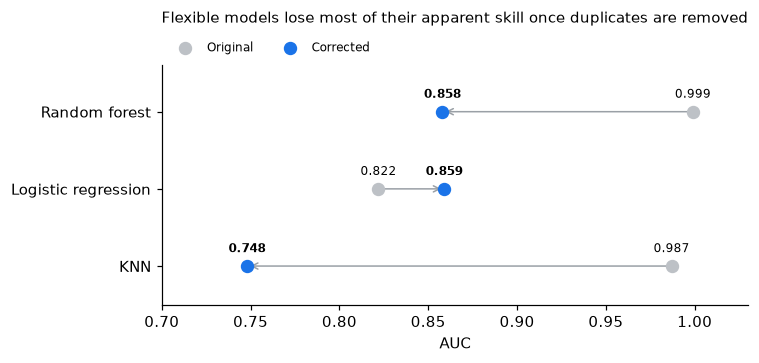

In [12]:
pivot = comparison.pivot(index="Model", columns="Setup", values="AUC")
fig, ax = plt.subplots(figsize=(7, 3.4))
for i, (model, row) in enumerate(pivot.iterrows()):
    before, after = row["Original (row-level split)"], row["Corrected (participant-level CV)"]
    ax.annotate("", xy=(after, i), xytext=(before, i), arrowprops=dict(arrowstyle="->", color="#9aa0a6"))
    ax.scatter(before, i, color="#bdc1c6", s=60, zorder=3, label="Original" if i == 0 else None)
    ax.scatter(after, i, color="#1a73e8", s=60, zorder=3, label="Corrected" if i == 0 else None)
    ax.text(before, i + 0.18, f"{before:.3f}", ha="center", fontsize=8)
    ax.text(after, i + 0.18, f"{after:.3f}", ha="center", fontsize=8, fontweight="bold")
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index)
ax.set_xlim(0.7, 1.03)
ax.set_ylim(-0.5, len(pivot) - 0.4)
ax.set_xlabel("AUC")
ax.set_title("Flexible models lose most of their apparent skill once duplicates are removed", fontsize=10, pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 6. How certain are the corrected AUCs?

A single AUC from 5,751 people and 232 cases can move by a few hundredths from sampling alone. Bootstrap the out-of-fold predictions (resample participants with replacement, 1,000 times) to get 95% confidence intervals, plus a paired comparison of logistic regression against random forest.

In [13]:
def bootstrap_auc(y_true, prob, n_boot=1000, seed=SEED):
    r = np.random.default_rng(seed)
    n = len(y_true)
    aucs = []
    for _ in range(n_boot):
        idx = r.integers(0, n, n)
        if y_true[idx].sum() == 0:
            continue
        aucs.append(roc_auc_score(y_true[idx], prob[idx]))
    aucs = np.array(aucs)
    return aucs.mean(), np.percentile(aucs, 2.5), np.percentile(aucs, 97.5), aucs

ci_rows, boot = [], {}
for name, prob in oof.items():
    m, lo, hi, samples = bootstrap_auc(y, prob)
    boot[name] = samples
    ci_rows.append({"Model": name, "AUC": round(roc_auc_score(y, prob), 3),
                    "CI_low": round(lo, 3), "CI_high": round(hi, 3)})
auc_ci = pd.DataFrame(ci_rows)
auc_ci.to_csv(OUT_DIR / "auc_bootstrap_ci.csv", index=False)

diff = boot["Logistic regression"] - boot["Random forest"]
print(f"LR minus RF AUC: {diff.mean():+.3f} (95% CI {np.percentile(diff, 2.5):+.3f} to {np.percentile(diff, 97.5):+.3f})")
auc_ci

LR minus RF AUC: +0.001 (95% CI -0.011 to +0.012)


,Model,AUC,CI_low,CI_high
0,Logistic regression,0.859,0.837,0.881
1,Random forest,0.858,0.835,0.879
2,KNN,0.748,0.713,0.781


## 7. Choosing a decision threshold for screening

The default 0.5 cutoff is arbitrary. For a screening use, missing a CHD case costs more than a false alarm, so the threshold should be chosen for a target sensitivity. The curve below (logistic regression, out-of-fold probabilities) shows what specificity is given up at each level of sensitivity; the table is exported for the Power BI "threshold" visual.

Youden-optimal threshold 0.40: sensitivity 0.86, specificity 0.72
Threshold for >=85% sensitivity 0.40: specificity 0.72, flags 31% of adults, PPV 0.11


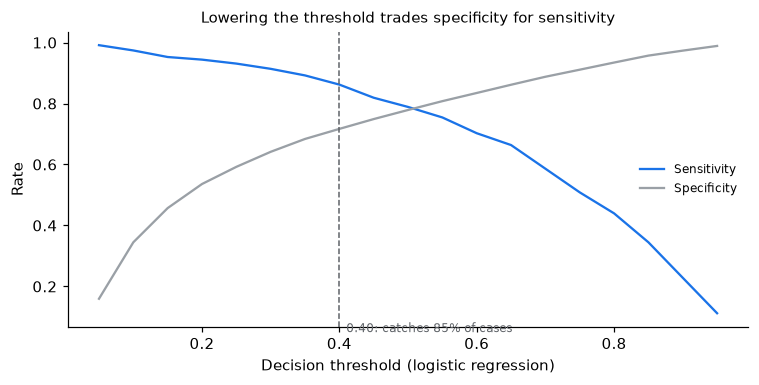

In [14]:
def threshold_table(y_true, prob, grid=np.round(np.arange(0.05, 0.96, 0.05), 2)):
    rows = []
    for t in grid:
        pred = (prob >= t).astype(int)
        tp = ((pred == 1) & (y_true == 1)).sum(); fn = ((pred == 0) & (y_true == 1)).sum()
        fp = ((pred == 1) & (y_true == 0)).sum(); tn = ((pred == 0) & (y_true == 0)).sum()
        rows.append({"Threshold": t, "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
                     "PPV": tp / max(tp + fp, 1), "FlaggedShare": (tp + fp) / len(y_true),
                     "Youden": tp / (tp + fn) + tn / (tn + fp) - 1})
    return pd.DataFrame(rows)

thr_tables = []
for name in ["Logistic regression", "Random forest"]:
    t = threshold_table(y, oof[name]); t.insert(0, "Model", name); thr_tables.append(t)
thresholds = pd.concat(thr_tables, ignore_index=True).round(4)
thresholds.to_csv(OUT_DIR / "threshold_curve.csv", index=False)

lr_t = thresholds[thresholds["Model"] == "Logistic regression"]
best = lr_t.loc[lr_t["Youden"].idxmax()]
target = lr_t[lr_t["Sensitivity"] >= 0.85].iloc[-1]  # highest threshold that still catches >=85% of cases
print(f"Youden-optimal threshold {best.Threshold:.2f}: sensitivity {best.Sensitivity:.2f}, specificity {best.Specificity:.2f}")
print(f"Threshold for >=85% sensitivity {target.Threshold:.2f}: specificity {target.Specificity:.2f}, "
      f"flags {target.FlaggedShare:.0%} of adults, PPV {target.PPV:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(lr_t["Threshold"], lr_t["Sensitivity"], color="#1a73e8", label="Sensitivity")
ax.plot(lr_t["Threshold"], lr_t["Specificity"], color="#9aa0a6", label="Specificity")
ax.axvline(target.Threshold, color="#5f6368", linestyle="--", linewidth=1)
ax.text(target.Threshold + 0.01, 0.05, f"{target.Threshold:.2f}: catches 85% of cases", fontsize=8, color="#5f6368")
ax.set_xlabel("Decision threshold (logistic regression)"); ax.set_ylabel("Rate")
ax.set_title("Lowering the threshold trades specificity for sensitivity", fontsize=10)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

## 8. SMOTE inside the fold versus class weighting

The original pipeline applied SMOTE before splitting, which manufactured synthetic copies of test participants. The fair version fits SMOTE **only on each training fold** (`imblearn.pipeline` does this automatically). Compare it with the class-weighting used above.

In [15]:
def cv_oof(estimator_factory, X, y, cv):
    prob = np.zeros(len(y))
    for tr, te in cv.split(X, y):
        pipe = estimator_factory()
        pipe.fit(X.iloc[tr], y[tr])
        prob[te] = pipe.predict_proba(X.iloc[te])[:, 1]
    return prob

smote_models = {
    "Logistic regression": lambda: ImbPipeline([("prep", preprocess), ("smote", SMOTE(random_state=SEED)),
                                                ("model", LogisticRegression(max_iter=2000))]),
    "Random forest": lambda: ImbPipeline([("prep", preprocess), ("smote", SMOTE(random_state=SEED)),
                                          ("model", RandomForestClassifier(n_estimators=300, random_state=SEED,
                                                                           n_jobs=-1, min_samples_leaf=5))]),
}
balance_rows = []
for name, factory in smote_models.items():
    p = cv_oof(factory, X, y, cv)
    oof[f"{name} (SMOTE in fold)"] = p
    balance_rows.append({"Model": name, "Balancing": "SMOTE inside each fold", **scores(y, p, 0.5)})
    balance_rows.append({"Model": name, "Balancing": "Class weights", **scores(y, oof[name], 0.5)})
balancing = pd.DataFrame(balance_rows).round(3)
balancing.to_csv(OUT_DIR / "balancing_comparison.csv", index=False)
balancing

,Model,Balancing,AUC,Accuracy,Sensitivity,Specificity
0,Logistic regression,SMOTE inside each fold,0.856,0.789,0.754,0.791
1,Logistic regression,Class weights,0.859,0.779,0.789,0.779
2,Random forest,SMOTE inside each fold,0.840,0.939,0.250,0.968
3,Random forest,Class weights,0.858,0.948,0.155,0.981


## 9. What drives the logistic-regression prediction?

Odds ratios per one standard deviation (numeric) or per category (one-hot), from the class-weighted logistic regression fit on all participants, with bootstrap 95% CIs. These are associations in cross-sectional, post-diagnosis data, not causal effects: the protective-looking cholesterol effect is consistent with statin treatment after diagnosis.

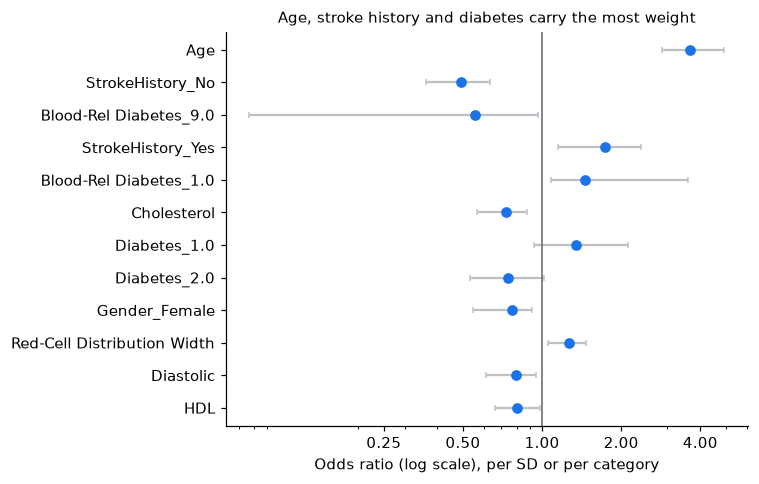

,Feature,OddsRatio,CI_low,CI_high,Direction,AbsLogOR
0,Age,3.665,2.862,4.935,Higher odds,1.299
29,StrokeHistory_No,0.490,0.362,0.632,Lower odds,0.714
28,Blood-Rel Diabetes_9.0,0.556,0.077,0.966,Lower odds,0.586
30,StrokeHistory_Yes,1.739,1.149,2.379,Higher odds,0.553
26,Blood-Rel Diabetes_1.0,1.452,1.077,3.587,Higher odds,0.373
5,Cholesterol,0.728,0.568,0.879,Lower odds,0.317
22,Diabetes_1.0,1.350,0.931,2.126,Higher odds,0.300
23,Diabetes_2.0,0.744,0.530,1.019,Lower odds,0.295
13,Gender_Female,0.766,0.547,0.916,Lower odds,0.267
4,Red-Cell Distribution Width,1.266,1.058,1.465,Higher odds,0.236


In [16]:
def fit_lr_coefs(X_fit, y_fit):
    pipe = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    pipe.fit(X_fit, y_fit)
    names = [n.split("__", 1)[-1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    return pd.Series(pipe.named_steps["model"].coef_.ravel(), index=names)

coef_full = fit_lr_coefs(X, y)
boot_coefs = []
for _ in range(200):
    idx = rng.integers(0, len(y), len(y))
    boot_coefs.append(fit_lr_coefs(X.iloc[idx], y[idx]).reindex(coef_full.index))
boot_coefs = pd.concat(boot_coefs, axis=1)

effects = pd.DataFrame({
    "Feature": coef_full.index,
    "OddsRatio": np.exp(coef_full.values),
    "CI_low": np.exp(boot_coefs.quantile(0.025, axis=1).values),
    "CI_high": np.exp(boot_coefs.quantile(0.975, axis=1).values),
})
effects["Direction"] = np.where(effects["OddsRatio"] >= 1, "Higher odds", "Lower odds")
effects["AbsLogOR"] = np.abs(np.log(effects["OddsRatio"]))
effects = effects.sort_values("AbsLogOR", ascending=False).round(3)
effects.to_csv(OUT_DIR / "lr_odds_ratios.csv", index=False)

top = effects.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(top["OddsRatio"], top["Feature"], xerr=[top["OddsRatio"] - top["CI_low"], top["CI_high"] - top["OddsRatio"]],
            fmt="o", color="#1a73e8", ecolor="#bdc1c6", capsize=2)
ax.axvline(1, color="#5f6368", linewidth=1); ax.set_xscale("log")
from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter
ax.xaxis.set_major_locator(FixedLocator([0.25, 0.5, 1, 2, 4])); ax.xaxis.set_major_formatter(ScalarFormatter()); ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Odds ratio (log scale), per SD or per category")
ax.set_title("Age, stroke history and diabetes carry the most weight", fontsize=10)
plt.tight_layout(); plt.show()
effects.head(12)

## 10. Calibration and clinical usefulness

AUC only measures ranking. A risk model also has to give **probabilities you can believe** (calibration) and has to be **worth using** at a realistic threshold (decision curve analysis, Vickers & Elkin 2006).

Class weighting (`class_weight="balanced"`) is a trick for ranking and for a 0.5 cutoff: it re-weights cases about 24 to 1, so predicted probabilities are inflated far above the true 4% risk. The comparison below includes an **unweighted** logistic regression, which keeps the same ranking but should be calibrated.

In [17]:
# Unweighted logistic regression, same folds and preprocessing
lr_unweighted = lambda: Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000))])
oof["Logistic regression (unweighted)"] = cv_oof(lr_unweighted, X, y, cv)

def calibration_stats(y_true, prob):
    prob = np.clip(prob, 1e-6, 1 - 1e-6)
    logit_p = np.log(prob / (1 - prob)).reshape(-1, 1)
    slope_fit = LogisticRegression(penalty=None, max_iter=1000).fit(logit_p, y_true)
    return {
        "AUC": roc_auc_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
        "MeanPredicted": prob.mean(),
        "ObservedRate": y_true.mean(),
        "CalibrationSlope": slope_fit.coef_[0, 0],   # ideal 1; < 1 = predictions too extreme
    }

cal_models = ["Logistic regression (unweighted)", "Logistic regression", "Random forest"]
cal_summary = pd.DataFrame([{"Model": m, **calibration_stats(y, oof[m])} for m in cal_models]).round(4)
cal_summary["Model"] = cal_summary["Model"].replace({"Logistic regression": "Logistic regression (class-weighted)",
                                                     "Random forest": "Random forest (class-weighted)"})
# Null model: predict the outcome rate for everyone
print(f"Brier score of the no-skill model (predict {y.mean():.3f} for everyone): {brier_score_loss(y, np.full(len(y), y.mean())):.4f}")
cal_summary.to_csv(OUT_DIR / "calibration_summary.csv", index=False)
cal_summary

Brier score of the no-skill model (predict 0.040 for everyone): 0.0387


C:\Users\zza16\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\zza16\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Model,AUC,Brier,MeanPredicted,ObservedRate,CalibrationSlope
0,Logistic regression (unweighted),0.8604,0.0352,0.0405,0.0403,0.9380
1,Logistic regression (class-weighted),0.8589,0.1506,0.3008,0.0403,0.7750
2,Random forest (class-weighted),0.8583,0.0443,0.1060,0.0403,1.0592


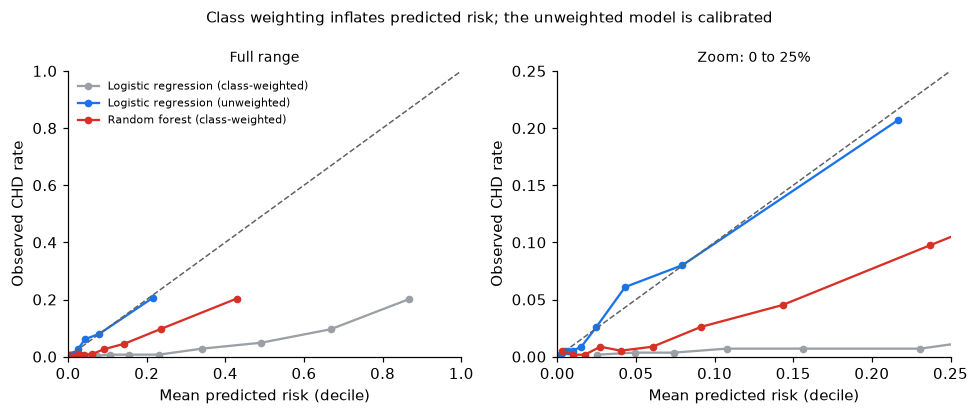

In [18]:
# Calibration curve: 10 risk groups (deciles of predicted risk) per model
rows = []
for m in cal_models:
    p = oof[m]
    bins = pd.qcut(p, 10, labels=False, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": y, "bin": bins}).groupby("bin")
    t = g.agg(MeanPredicted=("p", "mean"), Observed=("y", "mean"), n=("y", "size")).reset_index()
    t["Model"] = cal_summary.set_index(pd.Index(cal_models)).loc[m, "Model"]
    rows.append(t)
calibration = pd.concat(rows, ignore_index=True)[["Model", "bin", "n", "MeanPredicted", "Observed"]].round(4)
calibration.to_csv(OUT_DIR / "calibration_curve.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
colors = {"Logistic regression (unweighted)": "#1a73e8", "Logistic regression (class-weighted)": "#9aa0a6",
          "Random forest (class-weighted)": "#d93025"}
for name, t in calibration.groupby("Model"):
    for ax in axes:
        ax.plot(t["MeanPredicted"], t["Observed"], "o-", color=colors[name], label=name, ms=4)
for ax, lim in zip(axes, [1.0, 0.25]):
    ax.plot([0, lim], [0, lim], color="#5f6368", lw=1, ls="--")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel("Mean predicted risk (decile)"); ax.set_ylabel("Observed CHD rate")
axes[0].set_title("Full range", fontsize=9); axes[1].set_title("Zoom: 0 to 25%", fontsize=9)
axes[0].legend(frameon=False, fontsize=7, loc="upper left")
fig.suptitle("Class weighting inflates predicted risk; the unweighted model is calibrated", fontsize=10)
plt.tight_layout(); plt.show()

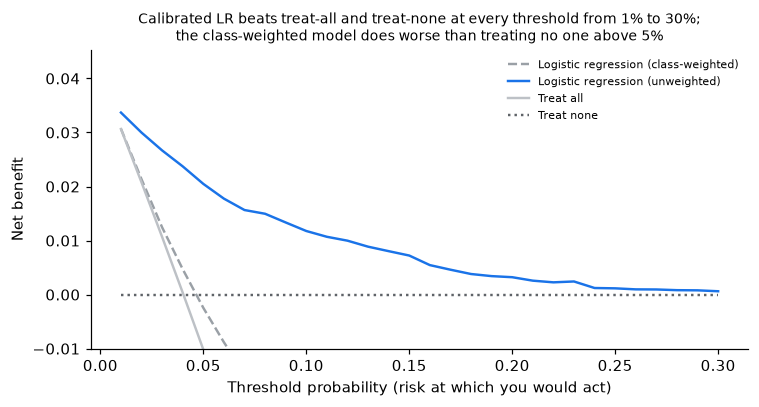

Class-weighted LR has negative net benefit from threshold 0.05
Unweighted LR beats both 'treat all' and 'treat none' for thresholds 0.01 to 0.30


Strategy,Logistic regression (class-weighted),Logistic regression (unweighted),Treat all,Treat none
Threshold,,,,
0.02,0.0213,0.0300,0.0208,0.0
0.05,-0.0024,0.0205,-0.0102,0.0
0.10,-0.0306,0.0118,-0.0663,0.0
0.15,-0.0535,0.0072,-0.1290,0.0
0.20,-0.0732,0.0032,-0.1996,0.0


In [19]:
# Decision curve analysis: net benefit across threshold probabilities a clinician might use
def net_benefit(y_true, prob, pt):
    pred = prob >= pt
    n = len(y_true)
    tp = (pred & (y_true == 1)).sum() / n
    fp = (pred & (y_true == 0)).sum() / n
    return tp - fp * pt / (1 - pt)

prev = y.mean()
grid = np.round(np.arange(0.01, 0.31, 0.01), 2)
dca_rows = []
for pt in grid:
    dca_rows.append({"Threshold": pt, "Strategy": "Treat all", "NetBenefit": prev - (1 - prev) * pt / (1 - pt)})
    dca_rows.append({"Threshold": pt, "Strategy": "Treat none", "NetBenefit": 0.0})
    for m, label in [("Logistic regression (unweighted)", "Logistic regression (unweighted)"),
                     ("Logistic regression", "Logistic regression (class-weighted)")]:
        dca_rows.append({"Threshold": pt, "Strategy": label, "NetBenefit": net_benefit(y, oof[m], pt)})
dca = pd.DataFrame(dca_rows).round(5)
dca.to_csv(OUT_DIR / "decision_curve.csv", index=False)

wide = dca.pivot(index="Threshold", columns="Strategy", values="NetBenefit")
useful = wide.index[(wide["Logistic regression (unweighted)"] > wide["Treat all"]) &
                    (wide["Logistic regression (unweighted)"] > 0)]
harm = wide.index[wide["Logistic regression (class-weighted)"] < 0]
fig, ax = plt.subplots(figsize=(7, 3.8))
style = {"Treat all": ("#bdc1c6", "-"), "Treat none": ("#5f6368", ":"),
         "Logistic regression (unweighted)": ("#1a73e8", "-"), "Logistic regression (class-weighted)": ("#9aa0a6", "--")}
for s, t in dca.groupby("Strategy"):
    ax.plot(t["Threshold"], t["NetBenefit"], color=style[s][0], ls=style[s][1], label=s, lw=1.6)
ax.set_ylim(-0.01, prev + 0.005)
ax.set_xlabel("Threshold probability (risk at which you would act)"); ax.set_ylabel("Net benefit")
ax.set_title(f"Calibrated LR beats treat-all and treat-none at every threshold from {useful.min():.0%} to {useful.max():.0%};\n"
             f"the class-weighted model does worse than treating no one above {harm.min():.0%}", fontsize=9)
ax.legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()

print(f"Class-weighted LR has negative net benefit from threshold {harm.min():.2f}")
print(f"Unweighted LR beats both 'treat all' and 'treat none' for thresholds {useful.min():.2f} to {useful.max():.2f}")
wide.loc[[0.02, 0.05, 0.10, 0.15, 0.20]].round(4)

## 11. Does the missing-data strategy change the conclusions?

Triglycerides are missing for 56% of participants because NHANES measures them only in the **morning fasting subsample** (about half of examinees, chosen at random by session). That is missing at random **by design**, so a model-based imputation should be close to unbiased, but mean imputation flattens the variable. The other labs are missing mostly for people who skipped the exam or blood draw.

Five strategies, all fit inside each fold of the same 5-fold split, logistic regression (class-weighted, as in the headline result). Complete-case analysis uses a smaller, different sample, so its AUC is not directly comparable; it is shown to make that point.

In [20]:
def make_preprocess(numeric_imputer, num_cols):
    return ColumnTransformer([
        ("num", Pipeline([("impute", numeric_imputer), ("scale", StandardScaler())]), num_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ])

numeric_no_tg = [c for c in numeric if c != "Triglycerides"]
strategies = {
    "Mean imputation (baseline)": (lambda: SimpleImputer(strategy="mean"), numeric, X, y),
    "Mean + missing indicators": (lambda: SimpleImputer(strategy="mean", add_indicator=True), numeric, X, y),
    "MICE (iterative imputation)": (lambda: IterativeImputer(max_iter=15, random_state=SEED, sample_posterior=False),
                                    numeric, X, y),
    "Drop triglycerides, mean-impute rest": (lambda: SimpleImputer(strategy="mean"), numeric_no_tg,
                                             X.drop(columns="Triglycerides"), y),
}
cc_mask = X[numeric].notna().all(axis=1).to_numpy()
strategies["Complete cases only"] = (lambda: SimpleImputer(strategy="mean"), numeric,
                                     X.loc[cc_mask].reset_index(drop=True), y[cc_mask])

miss_rows = []
for name, (imp, num_cols, X_s, y_s) in strategies.items():
    factory = lambda imp=imp, num_cols=num_cols: Pipeline([
        ("prep", make_preprocess(imp(), num_cols)),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
    cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    p = cv_oof(factory, X_s, y_s, cv_s)
    auc, lo, hi, _ = bootstrap_auc(y_s, p, n_boot=500)
    miss_rows.append({"Strategy": name, "N": len(y_s), "Cases": int(y_s.sum()),
                      "AUC": roc_auc_score(y_s, p), "CI_low": lo, "CI_high": hi,
                      **{k: v for k, v in scores(y_s, p, 0.5).items() if k in ("Sensitivity", "Specificity")}})
missing_sensitivity = pd.DataFrame(miss_rows).round(3)
missing_sensitivity.to_csv(OUT_DIR / "missing_sensitivity.csv", index=False)
missing_sensitivity

C:\Users\zza16\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


,Strategy,N,Cases,AUC,CI_low,CI_high,Sensitivity,Specificity
0,Mean imputation (baseline),5751,232,0.859,0.837,0.882,0.789,0.779
1,Mean + missing indicators,5751,232,0.857,0.835,0.880,0.789,0.783
2,MICE (iterative imputation),5751,232,0.860,0.838,0.883,0.789,0.782
3,"Drop triglycerides, mean-impute rest",5751,232,0.859,0.837,0.881,0.802,0.781
4,Complete cases only,2335,97,0.857,0.823,0.885,0.794,0.790


## 12. Survey-weighted prevalence for U.S. adults

Everything above describes the **sample**. NHANES over-samples some groups (older adults, Black, Hispanic and Asian Americans, low-income households), so unweighted rates are not U.S. rates. NCHS guidance: use the weight of the smallest subsample in the analysis. Groups here use exam and lab variables, so the weight is `WTMEC2YR`; strata `SDMVSTRA` (15) and PSUs `SDMVPSU` (2 per stratum) give 15 design degrees of freedom.

Implementation notes:
- **Domain estimation**, not subsetting: the variance uses every PSU in the full file, with people outside the domain contributing zero. Dropping them first would understate the SE.
- **Taylor linearization** of the ratio estimator, with-replacement PSU variance within strata (the default in R `survey` and `samplics`).
- **Logit-transformed 95% CI** with t(15), so intervals stay inside 0 to 1 for small prevalences (equivalent to `svyciprop(method = "logit")`).
- 179 cohort members were interviewed but not examined (`WTMEC2YR = 0`) and drop out of the weighted estimates.

The survey-weighted **logistic regression** follows in section 13. `analysis/svy_logistic.R` is an optional cross-check of both sections with R `survey`.

In [21]:
design_all = pd.read_csv(DATA_DIR / "raw" / "demographic.csv", usecols=["SEQN", "WTMEC2YR", "SDMVSTRA", "SDMVPSU"])
frame = design_all.merge(cohort.drop(columns=["WTMEC2YR", "SDMVSTRA", "SDMVPSU"]), on="SEQN", how="left")
frame["in_cohort"] = frame["CHD_Flag"].notna()
frame["CHD_Flag"] = frame["CHD_Flag"].fillna(0)
DESIGN_DF = frame.groupby("SDMVSTRA")["SDMVPSU"].nunique().sum() - frame["SDMVSTRA"].nunique()  # PSUs - strata = 15

def svy_prevalence(domain_mask):
    """Weighted proportion of CHD_Flag in a domain, Taylor-linearized SE over the full design."""
    w = frame["WTMEC2YR"].to_numpy() * domain_mask.to_numpy()
    yv = frame["CHD_Flag"].to_numpy()
    W = w.sum()
    p = (w * yv).sum() / W
    z = w * (yv - p) / W                      # linearized values; zero outside the domain
    tot = pd.DataFrame({"h": frame["SDMVSTRA"], "psu": frame["SDMVPSU"], "z": z}).groupby(["h", "psu"])["z"].sum()
    var = 0.0
    for h, zh in tot.groupby(level="h"):
        nh = len(zh)
        var += nh / (nh - 1) * ((zh - zh.mean()) ** 2).sum()
    se = np.sqrt(var)
    t = stats.t.ppf(0.975, DESIGN_DF)
    lg, se_lg = np.log(p / (1 - p)), se / (p * (1 - p))
    lo, hi = [1 / (1 + np.exp(-(lg + s * t * se_lg))) for s in (-1, 1)]
    n_unw = int((domain_mask & (frame["WTMEC2YR"] > 0)).sum())
    return {"WeightedPrevalence": p, "SE": se, "CI_low": lo, "CI_high": hi, "n": n_unw,
            "PopulationMillions": W / 1e6}

base = frame["in_cohort"] & (frame["WTMEC2YR"] > 0)
rows = [{"Factor": "All adults", "Level": "All adults", **svy_prevalence(base)}]
for name, col in groups.items():
    for level in sorted(frame.loc[base, col].dropna().unique()):
        if level in ("Missing", "Unknown"):
            continue
        rows.append({"Factor": name, "Level": level, **svy_prevalence(base & (frame[col] == level))})
weighted = pd.DataFrame(rows)

unw = prevalence.set_index(["Factor", "Level"])["Prevalence"]
weighted["UnweightedPrevalence"] = [cohort["CHD_Flag"].mean() if f == "All adults" else unw.get((f, l), np.nan)
                                    for f, l in zip(weighted["Factor"], weighted["Level"])]
weighted["DesignEffect"] = weighted["SE"] ** 2 / (weighted["WeightedPrevalence"] * (1 - weighted["WeightedPrevalence"]) / weighted["n"])
weighted = weighted.round(4)
weighted.to_csv(OUT_DIR / "weighted_prevalence.csv", index=False)
print(f"Design degrees of freedom: {DESIGN_DF}")
weighted[["Factor", "Level", "n", "UnweightedPrevalence", "WeightedPrevalence", "CI_low", "CI_high", "DesignEffect"]]

Design degrees of freedom: 15


,Factor,Level,n,UnweightedPrevalence,WeightedPrevalence,CI_low,CI_high,DesignEffect
0,All adults,All adults,5572,0.0403,0.0365,0.0283,0.0469,2.9641
1,Age group,20-39,1879,0.0031,0.0043,0.0014,0.0127,2.1110
2,Age group,40-59,1920,0.0208,0.0171,0.0089,0.0327,3.1481
3,Age group,60+,1773,0.1013,0.1071,0.0840,0.1356,2.6837
4,Sex,Female,2913,0.0310,0.0284,0.0182,0.0441,3.6696
5,Sex,Male,2659,0.0506,0.0453,0.0358,0.0571,1.5032
6,Blood pressure,1 Normal,2304,0.0282,0.0269,0.0186,0.0387,1.8707
7,Blood pressure,2 Elevated,825,0.0533,0.0456,0.0264,0.0777,2.5340
8,Blood pressure,3 Stage 1 hypertension,1032,0.0300,0.0313,0.0216,0.0451,0.9932
9,Blood pressure,4 Stage 2 hypertension,936,0.0726,0.0662,0.0434,0.0999,2.5578


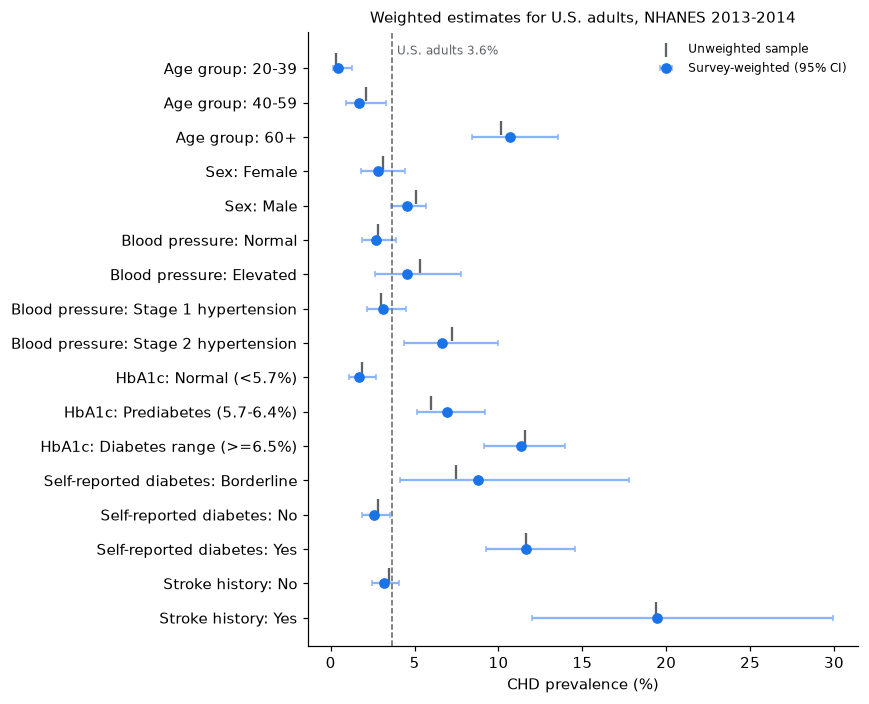

In [22]:
plot_w = weighted[weighted["Factor"] != "All adults"].iloc[::-1].reset_index(drop=True)
labels_w = plot_w["Factor"] + ": " + plot_w["Level"].astype(str).str.replace(r"^\d ", "", regex=True)
fig, ax = plt.subplots(figsize=(8, 6.5))
yy = np.arange(len(plot_w))
ax.errorbar(plot_w["WeightedPrevalence"] * 100, yy,
            xerr=[(plot_w["WeightedPrevalence"] - plot_w["CI_low"]) * 100, (plot_w["CI_high"] - plot_w["WeightedPrevalence"]) * 100],
            fmt="o", color="#1a73e8", ecolor="#8ab4f8", capsize=2, label="Survey-weighted (95% CI)")
ax.scatter(plot_w["UnweightedPrevalence"] * 100, yy + 0.25, marker="|", color="#5f6368", s=80, label="Unweighted sample")
overall_w = weighted.loc[weighted["Factor"] == "All adults", "WeightedPrevalence"].iloc[0] * 100
ax.axvline(overall_w, color="#5f6368", ls="--", lw=1)
ax.text(overall_w + 0.3, len(plot_w) - 0.6, f"U.S. adults {overall_w:.1f}%", fontsize=8, color="#5f6368")
ax.set_yticks(yy); ax.set_yticklabels(labels_w)
ax.set_xlabel("CHD prevalence (%)")
ax.set_title("Weighted estimates for U.S. adults, NHANES 2013-2014", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

## 13. Survey-weighted logistic regression

Which characteristics are associated with CHD **in the U.S. adult population**, with standard errors that respect the survey design?

**Estimator** (the one R `survey::svyglm` uses):
- Coefficients: weighted maximum likelihood, solving $\sum_i w_i x_i (y_i - p_i) = 0$ over the analysis domain (IRLS).
- Variance: the sandwich $A^{-1} B A^{-1}$, with $A = \sum_i w_i p_i(1-p_i) x_i x_i^\top$ and $B$ the between-PSU variance of the score totals $u_{hj} = \sum_{i \in (h,j)} w_i x_i (y_i - p_i)$ within strata (with-replacement, $\frac{n_h}{n_h-1}$ factor). People outside the domain contribute $u_i = 0$ but their PSUs stay in, which is domain estimation.
- Inference: Wald intervals with t on 15 design df. With about 21 coefficients and only 15 design df, R's `summary.svyglm` would print NaN p-values (residual df ≤ 0); using the design df is the usual NHANES practice.

**Missing data:** 20 imputations inside the cohort (`IterativeImputer` with posterior sampling and a different seed per imputation; outcome included in the imputation model; binary variables drawn as Bernoulli from their imputed probability; the 3 missing three-level diabetes answers by random hot deck). Pooled with Rubin's rules and Barnard-Rubin df (complete-data df = 15), as `mitools::MIcombine(df.complete = 15)` does. Sensitivity analysis: complete cases without triglycerides.

**Checks:** (1) an intercept-only model must reproduce the section-12 SE of overall prevalence on the logit scale; (2) a stratified delete-one-PSU jackknife (30 refits) must give SEs close to the sandwich for the complete-case model.

Predictors are on the per-SD scale (numeric, standardized on the cohort) or versus a reference category (female; no for yes/no items; no diabetes).

In [23]:
from scipy.special import expit

NUM_VARS = ["Age", "SystolicBP", "DiastolicBP", "TotalCholesterol", "HDL", "Triglycerides", "Glucose",
            "HbA1c", "Creatinine", "UricAcid", "LDH", "PlateletCount", "RDW"]
BIN_VARS = {"Sex": "Male", "VigorousWork": "Yes", "ModerateWork": "Yes",
            "FamilyHistoryDiabetes": "Yes", "StrokeHistory": "Yes"}      # value coded 1; the other level is reference

# Full design (all examined participants) with the cohort attached; non-cohort rows are outside the domain
svy = (design_all[design_all["WTMEC2YR"] > 0]
       .merge(cohort.drop(columns=["WTMEC2YR", "SDMVSTRA", "SDMVPSU"]), on="SEQN", how="left")
       .reset_index(drop=True))
svy["dom"] = svy["CHD_Flag"].notna()
STRATA, PSU, WT = svy["SDMVSTRA"].to_numpy(), svy["SDMVPSU"].to_numpy(), svy["WTMEC2YR"].to_numpy()

def design_matrix(df):
    """Per-SD numeric predictors + 0/1 indicators; NaN where missing."""
    out = pd.DataFrame(index=df.index)
    coh = df.loc[df["dom"]]
    for v in NUM_VARS:
        out[f"{v} (per SD)"] = (df[v] - coh[v].mean()) / coh[v].std()
    for v, one in BIN_VARS.items():
        s = df[v].where(~df[v].isin(["Unknown", "Missing"]))
        out[f"{v}: {one}"] = np.where(s.isna(), np.nan, (s == one).astype(float))
    dia = df["DiabetesSelfReport"].where(~df["DiabetesSelfReport"].isin(["Unknown"]))
    for lvl in ["Borderline", "Yes"]:
        out[f"Diabetes: {lvl}"] = np.where(dia.isna(), np.nan, (dia == lvl).astype(float))
    return out

def svy_logit(Xmat, yv, w, dom, max_iter=50):
    """Design-based logistic regression over a domain. Returns coef, sandwich vcov."""
    Xd = np.column_stack([np.ones(len(yv)), Xmat])
    wd = np.where(dom, w, 0.0)
    beta = np.zeros(Xd.shape[1])
    for _ in range(max_iter):
        p = expit(Xd @ beta)
        A = (Xd * (wd * p * (1 - p))[:, None]).T @ Xd
        step = np.linalg.solve(A, Xd.T @ (wd * (yv - p)))
        beta += step
        if np.max(np.abs(step)) < 1e-10:
            break
    p = expit(Xd @ beta)
    A = (Xd * (wd * p * (1 - p))[:, None]).T @ Xd
    U = Xd * (wd * (yv - p))[:, None]                     # zero outside the domain
    tot = pd.DataFrame(U).groupby([STRATA, PSU]).sum()
    B = np.zeros((Xd.shape[1], Xd.shape[1]))
    for h, g in tot.groupby(level=0):
        nh = len(g)
        dev = g.to_numpy() - g.to_numpy().mean(axis=0)
        B += nh / (nh - 1) * dev.T @ dev
    Ainv = np.linalg.inv(A)
    return beta, Ainv @ B @ Ainv

def or_table(beta, V, names, df, model):
    se = np.sqrt(np.diag(V)); t = stats.t.ppf(0.975, df)
    return pd.DataFrame({"Model": model, "Term": ["(Intercept)"] + names, "Coef": beta, "SE": se,
                         "OddsRatio": np.exp(beta), "CI_low": np.exp(beta - t * se), "CI_high": np.exp(beta + t * se),
                         "p": 2 * stats.t.sf(np.abs(beta / se), df), "df": df})

Xall = design_matrix(svy)
yall = svy["CHD_Flag"].fillna(0).to_numpy()
dom = svy["dom"].to_numpy()

# Check 1: intercept-only model reproduces the section-12 prevalence SE on the logit scale
b0, V0 = svy_logit(np.empty((len(yall), 0)), yall, WT, dom)
p_all = weighted.loc[weighted["Factor"] == "All adults"].iloc[0]
expected = p_all["SE"] / (p_all["WeightedPrevalence"] * (1 - p_all["WeightedPrevalence"]))
print(f"Intercept-only: p = {expit(b0[0]):.4f} (section 12: {p_all['WeightedPrevalence']:.4f}); "
      f"logit SE = {np.sqrt(V0[0, 0]):.4f} (section 12 implies {expected:.4f})")
assert abs(expit(b0[0]) - p_all["WeightedPrevalence"]) < 1e-4 and abs(np.sqrt(V0[0, 0]) - expected) < 2e-3

Intercept-only: p = 0.0365 (section 12: 0.0365); logit SE = 0.1230 (section 12 implies 0.1223)


In [24]:
# Complete-case model without triglycerides (sensitivity analysis) + jackknife check
cc_cols = [c for c in Xall.columns if not c.startswith("Triglycerides")]
cc_ok = dom & Xall[cc_cols].notna().all(axis=1).to_numpy()
Xcc = Xall[cc_cols].fillna(0).to_numpy()
b_cc, V_cc = svy_logit(Xcc, yall, WT, cc_ok)
cc_tab = or_table(b_cc, V_cc, cc_cols, DESIGN_DF, "Complete cases, no triglycerides")
print(f"Complete cases (examined, all predictors except triglycerides observed): n = {cc_ok.sum():,}, cases = {int(yall[cc_ok].sum())}")

# Check 2: stratified jackknife (JKn): drop one PSU, re-weight its stratum partner, refit
jk = []
pairs = pd.DataFrame({"h": STRATA, "j": PSU}).drop_duplicates().to_numpy()
for h, j in pairs:
    in_h = STRATA == h
    nh = len(np.unique(PSU[in_h]))
    wr = WT.copy()
    wr[in_h & (PSU == j)] = 0.0
    wr[in_h & (PSU != j)] *= nh / (nh - 1)
    bj, _ = svy_logit(Xcc, yall, wr, cc_ok)
    jk.append((nh - 1) / nh * (bj - b_cc) ** 2)
se_jk = np.sqrt(np.sum(jk, axis=0))
ratio = se_jk / np.sqrt(np.diag(V_cc))
print(f"Jackknife SE / sandwich SE across {len(ratio)} coefficients: median {np.median(ratio):.2f}, "
      f"range {ratio.min():.2f} to {ratio.max():.2f}")
assert 0.85 < np.median(ratio) < 1.15, "Sandwich and jackknife SEs disagree"


Complete cases (examined, all predictors except triglycerides observed): n = 4,760, cases = 199


Jackknife SE / sandwich SE across 20 coefficients: median 1.02, range 1.00 to 1.10


In [25]:
# Multiple imputation (m = 20) inside the cohort, then design-based fit on each and Rubin's rules
M = 20
coh_idx = np.flatnonzero(dom)
bin_cols = [c for c in Xall.columns if ":" in c and not c.startswith("Diabetes")]
dia_cols = ["Diabetes: Borderline", "Diabetes: Yes"]
imp_input = Xall.loc[coh_idx].drop(columns=dia_cols).copy()
imp_input["_CHD"] = yall[coh_idx]                      # outcome belongs in the imputation model
dia_obs = Xall.loc[coh_idx, dia_cols]

betas, variances = [], []
for k in range(M):
    r = np.random.default_rng(1000 + k)
    imp = IterativeImputer(sample_posterior=True, max_iter=10, random_state=1000 + k)
    filled = pd.DataFrame(imp.fit_transform(imp_input), columns=imp_input.columns, index=imp_input.index)
    for c in bin_cols:                                   # binary: Bernoulli draw from imputed probability
        miss = imp_input[c].isna()
        filled.loc[miss, c] = (r.random(miss.sum()) < filled.loc[miss, c].clip(0, 1)).astype(float)
    dia_k = dia_obs.copy()                               # 3-level diabetes: random hot deck (3 missing)
    miss = dia_k.isna().any(axis=1)
    donors = dia_obs.dropna()
    dia_k.loc[miss] = donors.sample(miss.sum(), replace=True, random_state=1000 + k).to_numpy()
    Xk = Xall.copy()
    Xk.loc[coh_idx, filled.columns.drop("_CHD")] = filled.drop(columns="_CHD").to_numpy()
    Xk.loc[coh_idx, dia_cols] = dia_k.to_numpy()
    b, V = svy_logit(Xk.fillna(0).to_numpy(), yall, WT, dom)
    betas.append(b); variances.append(V)

# Rubin's rules with Barnard-Rubin degrees of freedom (complete-data df = design df)
Q = np.array(betas); Qbar = Q.mean(axis=0)
Ubar = np.mean([np.diag(V) for V in variances], axis=0)
Bm = Q.var(axis=0, ddof=1)
T = Ubar + (1 + 1 / M) * Bm
lam = (1 + 1 / M) * Bm / T
nu_old = (M - 1) / np.maximum(lam, 1e-12) ** 2
nu_obs = (DESIGN_DF + 1) / (DESIGN_DF + 3) * DESIGN_DF * (1 - lam)
nu = 1 / (1 / nu_old + 1 / nu_obs)
tq = stats.t.ppf(0.975, nu); se_mi = np.sqrt(T)
mi_tab = pd.DataFrame({"Model": f"Multiple imputation (m={M})", "Term": ["(Intercept)"] + list(Xall.columns),
                       "Coef": Qbar, "SE": se_mi, "OddsRatio": np.exp(Qbar),
                       "CI_low": np.exp(Qbar - tq * se_mi), "CI_high": np.exp(Qbar + tq * se_mi),
                       "p": 2 * stats.t.sf(np.abs(Qbar / se_mi), nu), "df": nu,
                       "FractionMissingInfo": lam})

svy_or = pd.concat([mi_tab, cc_tab], ignore_index=True)
svy_or = svy_or[svy_or["Term"] != "(Intercept)"].round(4)
svy_or.to_csv(OUT_DIR / "svy_odds_ratios.csv", index=False)
show = svy_or[svy_or["Model"].str.startswith("Multiple")].sort_values("p")
show[["Term", "OddsRatio", "CI_low", "CI_high", "p", "df", "FractionMissingInfo"]]

,Term,OddsRatio,CI_low,CI_high,p,df,FractionMissingInfo
1,Age (per SD),3.5939,2.7223,4.7446,0.0000,13.2234,0.0082
17,FamilyHistoryDiabetes: Yes,1.8037,1.3910,2.3388,0.0003,13.0074,0.0241
13,RDW (per SD),1.2756,1.0777,1.5098,0.0081,12.9822,0.0259
3,DiastolicBP (per SD),0.8412,0.7445,0.9504,0.0094,12.2516,0.0775
4,TotalCholesterol (per SD),0.5903,0.4057,0.8590,0.0096,12.9808,0.0260
6,Triglycerides (per SD),1.3355,1.0763,1.6572,0.0140,9.3678,0.2710
8,HbA1c (per SD),1.3045,1.0209,1.6670,0.0357,13.1703,0.0121
18,StrokeHistory: Yes,2.1372,1.0180,4.4866,0.0454,13.2711,0.0047
12,PlateletCount (per SD),0.8340,0.6944,1.0017,0.0518,13.0924,0.0179
14,Sex: Male,1.5131,0.8262,2.7710,0.1633,13.2652,0.0051


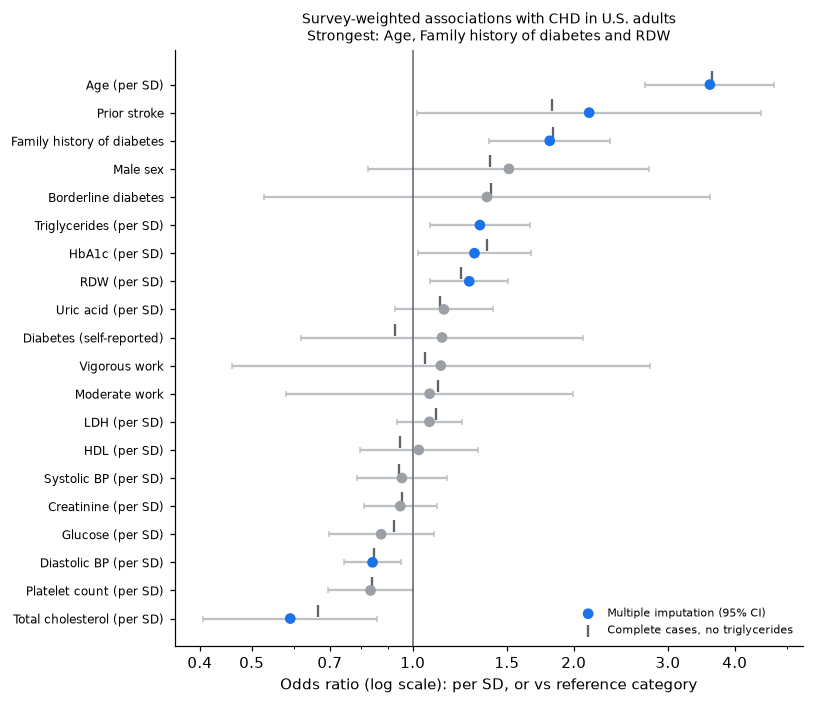

In [26]:
# Forest plot: survey-weighted ORs, multiple-imputation model, with the complete-case model for comparison
from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter
PRETTY = {"FamilyHistoryDiabetes: Yes": "Family history of diabetes", "StrokeHistory: Yes": "Prior stroke",
          "Sex: Male": "Male sex", "VigorousWork: Yes": "Vigorous work", "ModerateWork: Yes": "Moderate work",
          "Diabetes: Yes": "Diabetes (self-reported)", "Diabetes: Borderline": "Borderline diabetes",
          "TotalCholesterol (per SD)": "Total cholesterol (per SD)", "SystolicBP (per SD)": "Systolic BP (per SD)",
          "DiastolicBP (per SD)": "Diastolic BP (per SD)", "UricAcid (per SD)": "Uric acid (per SD)",
          "PlateletCount (per SD)": "Platelet count (per SD)"}
mi_plot = svy_or[svy_or["Model"].str.startswith("Multiple")].sort_values("OddsRatio").reset_index(drop=True)
cc_plot = svy_or[svy_or["Model"].str.startswith("Complete")].set_index("Term")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
yy = np.arange(len(mi_plot))
sig = (mi_plot["CI_low"] > 1) | (mi_plot["CI_high"] < 1)
ax.errorbar(mi_plot["OddsRatio"], yy, xerr=[mi_plot["OddsRatio"] - mi_plot["CI_low"], mi_plot["CI_high"] - mi_plot["OddsRatio"]],
            fmt="none", ecolor="#bdc1c6", capsize=2, zorder=1)
ax.scatter(mi_plot["OddsRatio"], yy, c=np.where(sig, "#1a73e8", "#9aa0a6"), s=36, zorder=3, label="Multiple imputation (95% CI)")
cc_vals = cc_plot.reindex(mi_plot["Term"])["OddsRatio"]
ax.scatter(cc_vals, yy + 0.28, marker="|", color="#5f6368", s=60, zorder=2, label="Complete cases, no triglycerides")
ax.axvline(1, color="#5f6368", lw=1); ax.set_xscale("log")
ax.set_yticks(yy); ax.set_yticklabels(mi_plot["Term"].map(lambda t: PRETTY.get(t, t)), fontsize=8)
ax.xaxis.set_major_locator(FixedLocator([0.4, 0.5, 0.7, 1, 1.5, 2, 3, 4]))
ax.xaxis.set_major_formatter(ScalarFormatter()); ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Odds ratio (log scale): per SD, or vs reference category")
top = mi_plot.loc[sig].sort_values("p").head(3)["Term"].map(lambda t: PRETTY.get(t, t).replace(" (per SD)", ""))
ax.set_title(f"Survey-weighted associations with CHD in U.S. adults\nStrongest: {top.iloc[0]}, {top.iloc[1]} and {top.iloc[2]}", fontsize=9)
ax.legend(frameon=False, fontsize=7, loc="lower right"); plt.tight_layout()
fig.savefig(ROOT / "docs" / "svy_forest.png", dpi=160, bbox_inches="tight"); plt.show()

## 14. Power BI export summary

Every table in `outputs/` is one row per entity, with sortable category labels, so it loads into Power BI without transformation:

| File | Grain | Used by |
|---|---|---|
| `nhanes_chd_cohort.csv` | one row per participant (incl. `WTMEC2YR`, strata, PSU) | slicers, KPI cards, weighted and unweighted prevalence (fact table) |
| `funnel.csv` | one row per audit step | rows-vs-participants funnel |
| `missingness.csv` | one row per lab variable | missingness bar |
| `prevalence_by_group.csv` | one row per factor level | prevalence small multiples |
| `model_comparison.csv` | one row per model x setup | original-vs-corrected AUC |
| `auc_bootstrap_ci.csv` | one row per model | error bars on AUC |
| `threshold_curve.csv` | one row per model x threshold | sensitivity/specificity line |
| `balancing_comparison.csv` | one row per model x balancing method | SMOTE vs class weights |
| `lr_odds_ratios.csv` | one row per feature | odds-ratio dot plot |
| `calibration_summary.csv` | one row per model | Brier / slope cards |
| `calibration_curve.csv` | one row per model x risk decile | calibration plot |
| `decision_curve.csv` | one row per strategy x threshold | decision curve |
| `missing_sensitivity.csv` | one row per missing-data strategy | sensitivity table |
| `weighted_prevalence.csv` | one row per factor level | weighted vs unweighted prevalence with CIs |
| `svy_odds_ratios.csv` | one row per model x term | survey-weighted odds-ratio forest plot |


In [27]:
for f in sorted(OUT_DIR.glob("*.csv")):
    print(f"{f.name:28s} {pd.read_csv(f).shape}")

auc_bootstrap_ci.csv         (3, 4)
balancing_comparison.csv     (4, 6)
calibration_curve.csv        (30, 5)
calibration_summary.csv      (3, 6)
decision_curve.csv           (120, 3)
funnel.csv                   (4, 3)
lr_odds_ratios.csv           (31, 6)
missing_sensitivity.csv      (5, 8)
missingness.csv              (12, 2)
model_comparison.csv         (6, 7)
nhanes_chd_cohort.csv        (5751, 30)
prevalence_by_group.csv      (17, 5)
svy_odds_ratios.csv          (39, 10)
threshold_curve.csv          (38, 7)
weighted_prevalence.csv      (18, 10)


## 15. Conclusions

**Data and leakage**
- The analysis cohort is **5,751 adults**, of whom **232 (4.0%)** reported CHD. The 15,103 figure counted rows, not people; the medications file (one row per prescription) multiplied every participant.
- About 75% of the original test rows had an exact copy in the training set, which explains the near-perfect random forest (AUC 0.999) and KNN (0.987) results.

**Discrimination**
- With participant-level cross-validation, logistic regression (AUC 0.859, 95% CI 0.837-0.881) and random forest (0.858, 0.835-0.879) are indistinguishable (paired difference +0.001, -0.011 to +0.012); KNN is clearly worse (0.745).
- SMOTE applied correctly, inside each fold, gives the same AUC as class weighting. The original 0.99 came from leakage, not from SMOTE.
- The result does not depend on the missing-data strategy: mean imputation, missing indicators, MICE and dropping triglycerides all give AUC 0.857-0.860.

**Calibration and usefulness**
- Class weighting inflates predicted risk (mean 30% vs an observed 4%; Brier 0.151, worse than the no-skill 0.039). The **unweighted** logistic regression is well calibrated (mean predicted 4.05% vs 4.03%, slope 0.94, Brier 0.035).
- Decision curve analysis: the calibrated model has higher net benefit than treating everyone or no one at every threshold from 1% to 30%. The class-weighted model does worse than treating no one above a 5% threshold. **Use class weighting for ranking, not for risk estimates.**

**Population estimates**
- Survey-weighted CHD prevalence among U.S. adults was **3.6% (95% CI 2.8-4.7%)**, about 8 million people, vs 4.0% in the unweighted sample. Weighted prevalence was 10.7% at age 60+, 11.6% with self-reported diabetes and 19.4% after a stroke. Design effects of about 2-3 mean the effective sample is a third to half of the nominal one.

**Population associations** (survey-weighted logistic regression, multiple imputation m = 20, all predictors mutually adjusted)
- Age (OR 3.59 per SD, 95% CI 2.72-4.74), family history of diabetes (1.80, 1.39-2.34), HbA1c (1.30 per SD), red-cell distribution width (1.28 per SD) and triglycerides (1.34 per SD) were associated with higher odds of CHD; prior stroke was borderline (2.14, 1.02-4.49).
- Total cholesterol (0.59 per SD, 0.41-0.86) and diastolic blood pressure (0.84 per SD) had **inverse** associations, the expected signature of treatment after diagnosis (statins, antihypertensives) in cross-sectional data.
- Self-reported diabetes added nothing once HbA1c was in the model. The complete-case model (n = 4,760) agreed in direction and size; there the stroke CI crossed 1.
- Design-based SEs were confirmed two ways: the intercept-only model reproduces the section-12 prevalence SE, and a 30-replicate stratified jackknife matched the sandwich SEs (median ratio 1.02).

**Limitations:** a self-reported, cross-sectional outcome (lab values were measured after diagnosis, and treatment such as statins can reverse apparent associations); about 11 events per coefficient in the adjusted model, so individual ORs are imprecise; no external validation (a later NHANES cycle would be the natural test set); the paper's PSO-ANN was not re-tested.
